In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# --- 1. READ AND CLEAN DATA ---
# Read the car info CSV file
# Note: Update the path string if your dataset moves
csv_path = r"C:\Users\Admin\Desktop\CS\ML Class\car data.csv"
car_info = pd.read_csv(csv_path)

# Convert all column names to lowercase for consistency
car_info.columns = [cols.lower() for cols in car_info.columns]

# --- 2. DATA EXPLORATION & ANALYSIS ---
print("--- Dataset Info ---")
print(car_info.info())

print("\n--- Missing Values Check ---")
print(car_info.isna().sum())

print("\n--- Descriptive Statistics ---")
print(car_info.describe())

print("\n--- Categorical Data Value Counts ---")
print(car_info["fuel_type"].value_counts())
print(car_info["seller_type"].value_counts())
print(car_info["transmission"].value_counts())

# --- 3. DATA VISUALIZATION ---
# Set matplotlib styling
plt.style.use("ggplot")

# Grouped Bar Charts for Categorical Data
fig_cat = plt.figure(figsize=(20, 5))
fig_cat.suptitle("Categorical Chart Info")

# Fuel type vs Selling price
plt.subplot(1, 3, 1)
plt.bar(car_info["fuel_type"], car_info["selling_price"], color="Red")
plt.xlabel("fuel_type")
plt.ylabel("selling_price")

# Seller type vs Selling price
plt.subplot(1, 3, 2)
plt.bar(car_info["seller_type"], car_info["selling_price"], color="Green")
plt.xlabel("seller_type")
plt.ylabel("selling_price")

# Transmission vs Selling price
plt.subplot(1, 3, 3)
plt.bar(car_info["transmission"], car_info["selling_price"], color="Blue")
plt.xlabel("transmission")
plt.ylabel("selling_price")
plt.tight_layout()

# Correlation Regression Plot
fig_reg = plt.figure(figsize=(10, 5))
plt.title("Correlation between present price and selling price")
sns.regplot(x=car_info["present_price"], y=car_info["selling_price"])

# Display the charts (VS Code requires plt.show() to render windows)
plt.show()

# --- 4. DATA PREPROCESSING & ENCODING ---
# Separate features and target output variable
input_data = car_info.drop(columns=["car_name", "selling_price"])
out_data = car_info["selling_price"]

# Convert categorical variables to dummy/indicator variables (One-Hot Encoding)
input_data = pd.get_dummies(input_data, dtype=int)

print("\n--- Processed Feature Headers ---")
print(input_data.head())

# Feature Scaling using StandardScaler
scaler = StandardScaler()
input_data_scaled = scaler.fit_transform(input_data)

# --- 5. MODEL TRAINING & SPLITTING ---
# Split data into training (80%) and testing sets (20%) with fixed random seed
X_train, X_test, y_train, y_test = train_test_split(
    input_data_scaled, out_data, test_size=0.2, random_state=42
)

# Instantiate and fit Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# --- 6. MODEL EVALUATION ---
# Generate predictions on test data
predicted_selling_price = model.predict(X_test)

# Calculate Evaluation Metrics
mae = mean_absolute_error(y_test, predicted_selling_price)
mse = mean_squared_error(y_test, predicted_selling_price)

print("\n--- Model Performance Evaluation ---")
print(f"Mean Absolute Error (MAE): {mae:.16f}")
print(f"Mean Squared Error (MSE):  {mse:.16f}")


In [3]:
# --- 1. READ AND CLEAN DATA ---
# Read the car info CSV file
# Note: Update the path string if your dataset moves
csv_path = r"C:\Users\Admin\Desktop\CS\ML Class\car data.csv"
car_info = pd.read_csv(csv_path)
car_info

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.90,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.00,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.50,9000,Diesel,Dealer,Manual,0


In [8]:
# Convert all column names to lowercase for consistency
car_info.columns = [cols.lower() for cols in car_info.columns]
car_info

,car_name,year,selling_price,present_price,kms_driven,fuel_type,seller_type,transmission,owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.90,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.00,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.50,9000,Diesel,Dealer,Manual,0


In [5]:
# --- 2. DATA EXPLORATION & ANALYSIS ---
print("--- Dataset Info ---")
print(car_info.info())

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   car_name       301 non-null    str    
 1   year           301 non-null    int64  
 2   selling_price  301 non-null    float64
 3   present_price  301 non-null    float64
 4   kms_driven     301 non-null    int64  
 5   fuel_type      301 non-null    str    
 6   seller_type    301 non-null    str    
 7   transmission   301 non-null    str    
 8   owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB
None


In [9]:
print("\n--- Missing Values Check ---")
print(car_info.isna().sum())


--- Missing Values Check ---
car_name         0
year             0
selling_price    0
present_price    0
kms_driven       0
fuel_type        0
seller_type      0
transmission     0
owner            0
dtype: int64


In [10]:
print("\n--- Descriptive Statistics ---")
print(car_info.describe())


--- Descriptive Statistics ---
              year  selling_price  present_price     kms_driven       owner
count   301.000000     301.000000     301.000000     301.000000  301.000000
mean   2013.627907       4.661296       7.628472   36947.205980    0.043189
std       2.891554       5.082812       8.644115   38886.883882    0.247915
min    2003.000000       0.100000       0.320000     500.000000    0.000000
25%    2012.000000       0.900000       1.200000   15000.000000    0.000000
50%    2014.000000       3.600000       6.400000   32000.000000    0.000000
75%    2016.000000       6.000000       9.900000   48767.000000    0.000000
max    2018.000000      35.000000      92.600000  500000.000000    3.000000


In [11]:
#explain categorical data
print(car_info["fuel_type"].value_counts())
print()
print(car_info["seller_type"].value_counts())
print()
print(car_info["transmission"].value_counts())

fuel_type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64

seller_type
Dealer        195
Individual    106
Name: count, dtype: int64

transmission
Manual       261
Automatic     40
Name: count, dtype: int64


In [12]:
import matplotlib.pyplot as plt
from matplotlib import style
style.available

['Solarize_Light2',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'petroff6',
 'petroff8',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

In [13]:
fuel_info = car_info["fuel_type"]
seller_info = car_info["seller_type"]
transmission_info = car_info["transmission"]
selling_price=car_info["selling_price"]

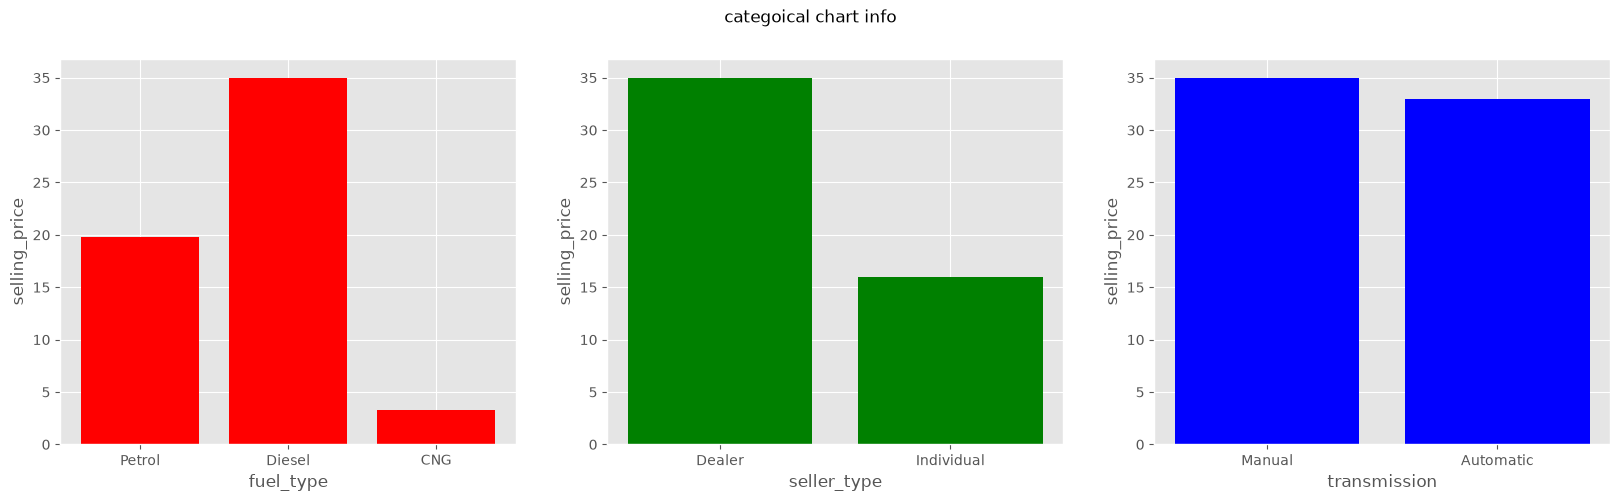

In [14]:
style.use("ggplot")
chart=plt.figure(figsize=(20,5))
chart.suptitle("categoical chart info")
plt.subplot(1,3,1)
plt.bar(fuel_info,selling_price,color="Red")
plt.xlabel("fuel_type")
plt.ylabel("selling_price")
plt.subplot(1,3,2)
plt.bar(seller_info,selling_price,color="Green")
plt.xlabel("seller_type")
plt.ylabel("selling_price")
plt.subplot(1,3,3)
plt.bar(transmission_info,selling_price,color="Blue")
plt.xlabel("transmission")
plt.ylabel("selling_price");

In [15]:
Petrol_data=car_info.groupby("fuel_type").get_group("Petrol")
Petrol_data.describe()

,year,selling_price,present_price,kms_driven,owner
count,239.000000,239.000000,239.000000,239.000000,239.000000
mean,2013.539749,3.264184,5.583556,33528.937238,0.050209
std,3.042674,3.135537,5.290685,40308.984886,0.270368
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.600000,0.940000,13850.000000,0.000000
50%,2014.000000,2.650000,4.600000,25870.000000,0.000000
75%,2016.000000,5.200000,7.980000,44271.000000,0.000000
max,2017.000000,19.750000,23.730000,500000.000000,3.000000


In [16]:
Diesel_data=car_info.groupby("fuel_type").get_group("Diesel")
Diesel_data.describe()

,year,selling_price,present_price,kms_driven,owner
count,60.000000,60.000000,60.000000,60.000000,60.000000
mean,2014.000000,10.278500,15.814500,50369.916667,0.016667
std,2.201694,7.185159,13.484289,30021.446979,0.129099
min,2005.000000,3.100000,5.700000,2071.000000,0.000000
25%,2013.000000,5.137500,8.912500,38750.000000,0.000000
50%,2014.000000,7.750000,10.585000,45000.000000,0.000000
75%,2015.000000,12.600000,17.010000,59250.000000,0.000000
max,2018.000000,35.000000,92.600000,197176.000000,1.000000


In [18]:
#converting categorical to numerical data
car_info.replace({"fuel_type":{"Petrol":0,"Diesel":1,"CNG":2}},inplace=True)

,car_name,year,selling_price,present_price,kms_driven,fuel_type,seller_type,transmission,owner
0,ritz,2014,3.35,5.59,27000,0,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,1,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,0,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,0,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,1,Dealer,Manual,0
...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,1,Dealer,Manual,0
297,brio,2015,4.00,5.90,60000,0,Dealer,Manual,0
298,city,2009,3.35,11.00,87934,0,Dealer,Manual,0
299,city,2017,11.50,12.50,9000,1,Dealer,Manual,0


In [19]:
print(car_info["fuel_type"])

0      0
1      1
2      0
3      0
4      1
      ..
296    1
297    0
298    0
299    1
300    0
Name: fuel_type, Length: 301, dtype: object


In [20]:
car_info.replace({"seller_type":{"Dealer":0,"Individual":1}},inplace=True)

,car_name,year,selling_price,present_price,kms_driven,fuel_type,seller_type,transmission,owner
0,ritz,2014,3.35,5.59,27000,0,0,Manual,0
1,sx4,2013,4.75,9.54,43000,1,0,Manual,0
2,ciaz,2017,7.25,9.85,6900,0,0,Manual,0
3,wagon r,2011,2.85,4.15,5200,0,0,Manual,0
4,swift,2014,4.60,6.87,42450,1,0,Manual,0
...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,1,0,Manual,0
297,brio,2015,4.00,5.90,60000,0,0,Manual,0
298,city,2009,3.35,11.00,87934,0,0,Manual,0
299,city,2017,11.50,12.50,9000,1,0,Manual,0


In [21]:
print(car_info["seller_type"])

0      0
1      0
2      0
3      0
4      0
      ..
296    0
297    0
298    0
299    0
300    0
Name: seller_type, Length: 301, dtype: object


In [22]:
car_info.replace({"transmission":{"Manual":0,"Automatic":1,}},inplace=True)

,car_name,year,selling_price,present_price,kms_driven,fuel_type,seller_type,transmission,owner
0,ritz,2014,3.35,5.59,27000,0,0,0,0
1,sx4,2013,4.75,9.54,43000,1,0,0,0
2,ciaz,2017,7.25,9.85,6900,0,0,0,0
3,wagon r,2011,2.85,4.15,5200,0,0,0,0
4,swift,2014,4.60,6.87,42450,1,0,0,0
...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,1,0,0,0
297,brio,2015,4.00,5.90,60000,0,0,0,0
298,city,2009,3.35,11.00,87934,0,0,0,0
299,city,2017,11.50,12.50,9000,1,0,0,0


In [23]:
car_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   car_name       301 non-null    str    
 1   year           301 non-null    int64  
 2   selling_price  301 non-null    float64
 3   present_price  301 non-null    float64
 4   kms_driven     301 non-null    int64  
 5   fuel_type      301 non-null    object 
 6   seller_type    301 non-null    object 
 7   transmission   301 non-null    object 
 8   owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(3), str(1)
memory usage: 21.3+ KB


In [24]:
car_info.describe()

,year,selling_price,present_price,kms_driven,owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [25]:
car_info

,car_name,year,selling_price,present_price,kms_driven,fuel_type,seller_type,transmission,owner
0,ritz,2014,3.35,5.59,27000,0,0,0,0
1,sx4,2013,4.75,9.54,43000,1,0,0,0
2,ciaz,2017,7.25,9.85,6900,0,0,0,0
3,wagon r,2011,2.85,4.15,5200,0,0,0,0
4,swift,2014,4.60,6.87,42450,1,0,0,0
...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,1,0,0,0
297,brio,2015,4.00,5.90,60000,0,0,0,0
298,city,2009,3.35,11.00,87934,0,0,0,0
299,city,2017,11.50,12.50,9000,1,0,0,0


In [26]:
car_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   car_name       301 non-null    str    
 1   year           301 non-null    int64  
 2   selling_price  301 non-null    float64
 3   present_price  301 non-null    float64
 4   kms_driven     301 non-null    int64  
 5   fuel_type      301 non-null    object 
 6   seller_type    301 non-null    object 
 7   transmission   301 non-null    object 
 8   owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(3), str(1)
memory usage: 21.3+ KB


In [27]:
car_info.describe()

,year,selling_price,present_price,kms_driven,owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [29]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


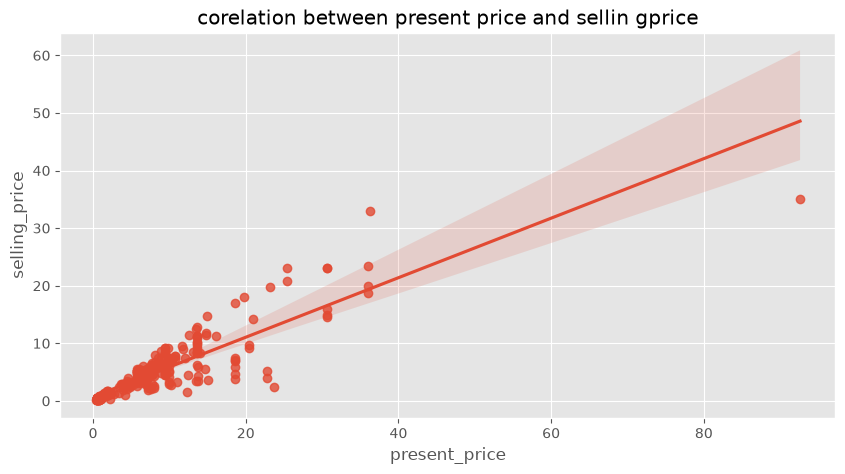

In [30]:
import seaborn as sns
fig=plt.figure(figsize=(10,5))
plt.title("corelation between present price and sellin gprice")
sns.regplot(x=car_info["present_price"],y=car_info["selling_price"]);

In [31]:
#input and output data
input_data=car_info.drop(columns=["car_name","selling_price"])
out_data=car_info["selling_price"]
input_data.head()

,year,present_price,kms_driven,fuel_type,seller_type,transmission,owner
0,2014,5.59,27000,0,0,0,0
1,2013,9.54,43000,1,0,0,0
2,2017,9.85,6900,0,0,0,0
3,2011,4.15,5200,0,0,0,0
4,2014,6.87,42450,1,0,0,0


In [32]:
out_data.head()

0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: selling_price, dtype: float64

In [33]:
input_data.shape

(301, 7)

In [34]:
out_data.shape

(301,)

In [35]:
input_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year           301 non-null    int64  
 1   present_price  301 non-null    float64
 2   kms_driven     301 non-null    int64  
 3   fuel_type      301 non-null    object 
 4   seller_type    301 non-null    object 
 5   transmission   301 non-null    object 
 6   owner          301 non-null    int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 16.6+ KB


In [36]:
input_data = pd.get_dummies(input_data, dtype=int)
print(input_data.head())

   year  present_price  kms_driven  owner  fuel_type_0  fuel_type_1  \
0  2014           5.59       27000      0            1            0   
1  2013           9.54       43000      0            0            1   
2  2017           9.85        6900      0            1            0   
3  2011           4.15        5200      0            1            0   
4  2014           6.87       42450      0            0            1   

   fuel_type_2  seller_type_0  seller_type_1  transmission_0  transmission_1  
0            0              1              0               1               0  
1            0              1              0               1               0  
2            0              1              0               1               0  
3            0              1              0               1               0  
4            0              1              0               1               0  


In [37]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
input_data = scaler.fit_transform(input_data)
print(input_data)

[[ 0.128897   -0.23621461 -0.25622446 ... -0.73728539  0.39148015
  -0.39148015]
 [-0.21751369  0.22150462  0.1559105  ... -0.73728539  0.39148015
  -0.39148015]
 [ 1.16812909  0.25742689 -0.77396901 ... -0.73728539  0.39148015
  -0.39148015]
 ...
 [-1.60315648  0.39068691  1.31334003 ... -0.73728539  0.39148015
  -0.39148015]
 [ 1.16812909  0.56450434 -0.7198763  ... -0.73728539  0.39148015
  -0.39148015]
 [ 0.8217184  -0.20029235 -0.81095812 ... -0.73728539  0.39148015
  -0.39148015]]


In [42]:
from sklearn.model_selection import train_test_split

input_data_train, input_data_test, output_data_train, output_data_test = train_test_split(input_data, out_data, test_size=0.2)

print(input_data_train.shape)

(240, 11)


In [43]:
print(input_data_test.shape)

(61, 11)


In [44]:
from sklearn.linear_model import LinearRegression
from sklearn import metrics
model=LinearRegression()
model.fit(input_data_train,output_data_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[ 1.08, 4.4 ,-0.29,...,-0.1 ,-0.17, 0.17]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.783
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](11,)","[27.26,22.66,19.99,..., 0. , 0. , 0. ]"


In [45]:
predicted_selling_price = model.predict(input_data_test)

In [46]:
predicted_selling_price

array([ 3.41144312,  1.11266323,  8.13086714, 11.38843684,  5.23603497,
        8.82950905,  2.11050935,  6.3196596 , 18.09555355, 21.92949889,
        0.88543214,  6.43229231,  5.81886685,  5.25460294,  1.00371274,
        6.95619761,  1.6142321 ,  1.30184564, 11.54324615,  0.59419445,
       -0.91287084,  2.95239028, -1.74122948,  2.17796677,  7.80834706,
        5.99009521,  8.49749627,  1.22506455, 10.33051259,  6.09047215,
        3.72767668,  3.92061815,  2.73833813,  4.20936978,  7.41813781,
        2.60643078,  1.17287876,  9.39634626,  2.9297372 , -0.37003432,
        1.76545115,  6.83344651, 10.31401176,  8.13864066,  4.02053445,
        1.56366385, 47.99132637,  2.43818323,  0.3510241 ,  8.03859362,
        6.67729004,  5.48448786,  1.91539346,  7.50853132,  2.85963687,
        1.55575057,  3.20324475,  4.11150557,  0.84204461,  8.46613441,
       19.58562502])

In [47]:
from sklearn.metrics import mean_absolute_error,mean_squared_error

In [50]:
print("mean absolute error",(metrics.mean_absolute_error(predicted_selling_price,output_data_test)))
print("mean square error",(metrics.mean_squared_error(predicted_selling_price,output_data_test)))

mean absolute error 1.4066878972171142
mean square error 5.4575744871637575
